# Laboratorio de monitoreo

Este notebook simula tres años de producción del modelo de riesgo, de enero de 2023 a diciembre de 2025. Para cada mes ejecuta `monthly_cycle` de `flows.py`, el mismo flujo que programarías en producción. El flujo valida los datos, puntúa las solicitudes, monitorea y, cuando toca, reentrena. Al final inyecta dos incidentes de datos y muestra qué detector atrapa cada uno.

El notebook trabaja en una carpeta temporal con su propio lago de datos y su propia base de MLflow (SQLite). No toca tu carpeta `data/` ni tu servidor de MLflow, y no necesita un servidor de Prefect.

Lo acompaña la [guía 06](../docs/guias/06-monitoreo-y-reentrenamiento.md). Ejecútalo con **Run All Cells**.

## 1. Un entorno aislado

Las variables de entorno `CREDIT_MLOPS_*` cambian la configuración sin editar `config/settings.toml`, igual que el `.env` de la guía 02. Aquí apuntan los datos y MLflow a una carpeta temporal.

In [1]:
import logging
import os
import tempfile
import warnings
from pathlib import Path

workdir = Path(tempfile.mkdtemp(prefix="lab-monitoreo-"))
os.environ["CREDIT_MLOPS_DATA_DIR"] = str(workdir / "data")
os.environ["CREDIT_MLOPS_MLFLOW_TRACKING_URI"] = f"sqlite:///{(workdir / 'mlflow.db').as_posix()}"
os.environ["CREDIT_MLOPS_MLFLOW_ARTIFACT_ROOT"] = (workdir / "mlartifacts").as_uri()
os.environ.pop("CREDIT_MLOPS_MLFLOW_REGISTRY_URI", None)
os.environ.pop("MLFLOW_REGISTRY_URI", None)

# Quieter output: libraries show only warnings and errors, no progress bars or telemetry.
logging.disable(logging.INFO)
warnings.filterwarnings("ignore", category=UserWarning)
warnings.filterwarnings("ignore", message="IProgress not found")
os.environ["PREFECT_LOGGING_LEVEL"] = "WARNING"
os.environ["PREFECT_SERVER_ANALYTICS_ENABLED"] = "false"
os.environ["MLFLOW_ENABLE_ARTIFACTS_PROGRESS_BAR"] = "false"
print("Entorno temporal listo: datos y MLflow fuera de tu repositorio")

Entorno temporal listo: datos y MLflow fuera de tu repositorio


## 2. El lago de datos y el champion inicial

Genera el mismo lago que `credit-mlops simulate` (2500 préstamos por mes, de 2019 a 2025) y entrena el modelo de la guía 03 con la ventana por defecto. El gate lo promueve a `@champion` porque todavía no hay otro.

In [2]:
import shutil
from datetime import date

import matplotlib.pyplot as plt
import pandas as pd
from prefect.testing.utilities import prefect_test_harness
from scipy.stats import norm

from credit_mlops.flows import monthly_cycle, next_streak, simulate_production
from credit_mlops.registry.gate import promote
from credit_mlops.registry.logging import log_and_register
from credit_mlops.schema import FEATURES
from credit_mlops.settings import DEFAULT_WINDOW, Settings, TrainingWindow
from credit_mlops.simulation.config import (
    LAB_BUREAU_SHIFT_MONTH,
    LAB_INCOME_BUG_MONTH,
    IncidentConfig,
    SimulationConfig,
)
from credit_mlops.simulation.generator import simulate, write_lake
from credit_mlops.training.train import train_model

logging.getLogger("mlflow").setLevel(logging.ERROR)  # hide MLflow's packaging warnings
plt.rcParams.update({"figure.dpi": 72, "font.size": 9})

settings = Settings()
lake = simulate(SimulationConfig())
write_lake(lake, settings.data_dir)
n_months = lake.applications["origination_month"].nunique()
print(f"Lago: {n_months} meses, {len(lake.applications)} préstamos")

first = log_and_register(settings, train_model(settings, DEFAULT_WINDOW), repo_root=Path.cwd())
decision = promote(settings)
print(f"Champion inicial: v{first.version}, AUC fuera de tiempo {decision.challenger.roc_auc:.3f}")

Lago: 84 meses, 210000 préstamos


Successfully registered model 'credit_default_pd'.
Created version '1' of model 'credit_default_pd'.


Champion inicial: v1, AUC fuera de tiempo 0.804


## 3. Tres años de producción

`simulate_production` llama a `monthly_cycle` mes por mes y le pasa la racha de alertas del mes anterior. Cuando la racha llega a 6 meses seguidos con alerta de performance, el flujo entrena un challenger con una ventana móvil y el gate decide si lo promueve. `prefect_test_harness` levanta un servidor de Prefect temporal solo para este notebook.

Es la celda más lenta del notebook.

In [3]:
with prefect_test_harness():
    results = simulate_production("2023-01", "2025-12")

reports = {r.month: r.report for r in results}
retrain = next(r for r in results if r.retrained)
outcome = "gate aprobado" if retrain.gate.promote else "gate rechazado"
print(f"{len(results)} meses procesados")
print(f"reentrenamiento en {retrain.month}: {outcome}, nuevo champion v{retrain.retrained.version}")

Registered model 'credit_default_pd' already exists. Creating a new version of this model...
Created version '2' of model 'credit_default_pd'.


36 meses procesados
reentrenamiento en 2024-12: gate aprobado, nuevo champion v2


## 4. El estado de cada mes

Cada mes termina en uno de cuatro estados. Si se cumple más de uno, gana el primero de esta lista:

1. `block`: el contrato de datos falló. No se puntúa el mes.
2. `investigate`: algún PSI llegó al umbral de acción (0.25). Puede ser un bug o un cambio real, y lo decide una persona.
3. `retrain`: alerta de performance con etiquetas maduras.
4. `ok`.

In [4]:
status = pd.DataFrame(
    [(r.month[:4], r.month[5:], r.status) for r in results], columns=["año", "mes", "estado"]
)
status.pivot(index="año", columns="mes", values="estado")

mes,01,02,03,04,05,06,07,08,09,10,11,12
año,,,,,,,,,,,,
2023,ok,ok,ok,ok,ok,ok,ok,ok,ok,ok,ok,ok
2024,ok,ok,ok,ok,ok,ok,retrain,retrain,retrain,retrain,retrain,retrain
2025,ok,ok,ok,ok,ok,ok,ok,ok,ok,ok,ok,ok


Todo 2023 y la primera mitad de 2024 están en `ok`. Las alertas empiezan en 2024-07 y siguen seis meses. En 2024-12 el flujo reentrena, y en 2025 el nuevo champion vuelve a `ok`.

## 5. Drift: PSI contra la referencia del modelo

En cada mes el monitoreo compara la distribución de cada variable con una muestra de referencia. El entrenamiento guardó esa muestra como artefacto del champion. La referencia pertenece al modelo, no al mes anterior. La línea vertical marca la promoción del nuevo champion, que trae su propia referencia.

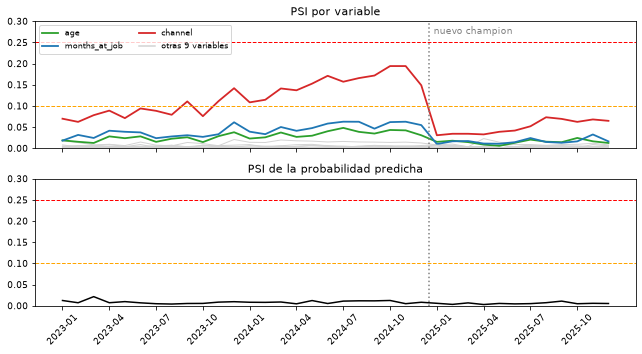

In [5]:
# The monitoring code draws its drift plots with the file-only Agg backend; show plots here again.
%matplotlib inline

months = [r.month for r in results]
x = range(len(months))
promotion = months.index(retrain.month) + 0.5  # after the 2024-12 cycle
watch, act = settings.psi_watch, settings.psi_act
highlight = {"channel": "tab:red", "months_at_job": "tab:blue", "age": "tab:green"}

fig, (top, bottom) = plt.subplots(2, 1, figsize=(9, 5), sharex=True)
for feature in FEATURES:
    values = [reports[m].feature_psi.get(feature) for m in months]
    if feature in highlight:
        top.plot(x, values, color=highlight[feature], label=feature, linewidth=1.8)
    else:
        top.plot(x, values, color="lightgray", linewidth=1)
top.plot([], [], color="lightgray", label="otras 9 variables")
bottom.plot(x, [reports[m].prediction_psi for m in months], color="black")
for ax, title in ((top, "PSI por variable"), (bottom, "PSI de la probabilidad predicha")):
    ax.axhline(watch, color="orange", linestyle="--", linewidth=1)
    ax.axhline(act, color="red", linestyle="--", linewidth=1)
    ax.axvline(promotion, color="gray", linestyle=":")
    ax.set_ylim(0, 0.3)
    ax.set_title(title)
top.text(promotion + 0.3, 0.27, "nuevo champion", color="gray")
top.legend(loc="upper left", ncol=2, fontsize=8)
bottom.set_xticks(list(x)[::3], months[::3], rotation=45)
fig.tight_layout()
plt.show()

In [6]:
psi_table = pd.DataFrame(
    {
        "channel": [reports[m].feature_psi["channel"] for m in months],
        "predicción": [reports[m].prediction_psi for m in months],
        "versión": [reports[m].model_version for m in months],
    },
    index=months,
)
psi_table.loc[["2023-01", "2024-07", "2024-12", "2025-01", "2025-12"]].round(3)

,channel,predicción,versión
2023-01,0.070,0.012,1
2024-07,0.157,0.011,1
2024-12,0.149,0.008,1
2025-01,0.031,0.006,2
2025-12,0.065,0.005,2


Tres lecturas:

- `channel` crece porque cada año más solicitudes llegan por el canal digital. Pasa la zona de vigilancia (0.10, línea naranja) en 2023 y se queda debajo del umbral de acción (0.25, línea roja). El reporte lo menciona como `PSI watch` pero el estado sigue en `ok`.
- Con el nuevo champion el PSI de `channel` baja, porque la referencia ahora es una muestra de su ventana de entrenamiento, que ya tiene más solicitudes digitales.
- El PSI de la predicción nunca sube. Desde 2023-07 los préstamos de la región norte tienen más riesgo, pero sus variables no cambian. Lo que cambia es la probabilidad de default para un mismo perfil. El PSI mira las entradas y la salida del modelo, no los resultados, así que no puede ver este shock.

## 6. Performance con etiquetas maduras

Un préstamo se marca como default si cae en default dentro de sus primeros 12 meses. En el mes M solo conoces el resultado de los préstamos originados 12 o más meses antes. El monitoreo junta las 3 cohortes más recientes ya maduras (M-12, M-13 y M-14), toma las predicciones que el champion actual hizo para ellas y compara la PD promedio con la tasa de default observada. La razón de calibración es la PD promedio dividida entre la tasa observada. Un valor de 1.0 es perfecto, y uno menor que 1 significa que el modelo subestima el riesgo. Solo cuentan las regiones con al menos 500 préstamos en esas 3 cohortes.

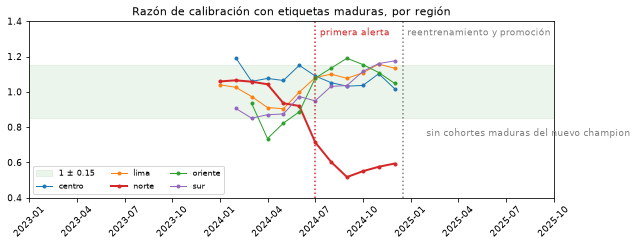

In [7]:
def region_metric(month, region, field):
    """A matured-label metric of one region, or None when there is nothing to judge."""
    performance = reports[month].performance
    segment = performance.metrics.by_segment.get(region) if performance else None
    return getattr(segment, field) if segment else None


colors = {
    "centro": "tab:blue",
    "lima": "tab:orange",
    "norte": "tab:red",
    "oriente": "tab:green",
    "sur": "tab:purple",
}
regions = list(colors)
calibration = pd.DataFrame(
    {region: [region_metric(m, region, "calibration_ratio") for m in months] for region in regions},
    index=months,
)

first_alert = months.index(next(r.month for r in results if r.report.performance_alert))
tol = settings.calibration_tolerance
fig, ax = plt.subplots(figsize=(9, 3.5))
ax.axhspan(1 - tol, 1 + tol, color="green", alpha=0.08, label=f"1 ± {tol}")
for region in regions:
    width = 2 if region == "norte" else 1
    ax.plot(x, calibration[region], marker=".", label=region, color=colors[region], linewidth=width)
ax.axvline(first_alert, color="tab:red", linestyle=":")
ax.axvline(promotion, color="gray", linestyle=":")
ax.text(first_alert + 0.3, 1.32, "primera alerta", color="tab:red")
ax.text(promotion + 0.3, 1.32, "reentrenamiento y promoción", color="gray")
ax.text(promotion + 1.5, 0.75, "sin cohortes maduras del nuevo champion", color="gray")
ax.set_ylim(0.4, 1.4)
ax.set_xticks(list(x)[::3], months[::3], rotation=45)
ax.set_title("Razón de calibración con etiquetas maduras, por región")
ax.legend(loc="lower left", ncol=3, fontsize=8)
fig.tight_layout()
plt.show()

La calibración de norte cae debajo de la banda cuando maduran las primeras cohortes del shock (originadas desde 2023-07, maduras desde 2024-07). Antes de eso el modelo ya puntuaba mal a esos clientes, pero nadie podía saberlo.

La tabla siguiente muestra, mes a mes en 2024, la razón de calibración y el estadístico z de norte y oriente, los préstamos de oriente en las 3 cohortes y la racha de alertas que lleva el flujo.

In [8]:
streak = 0
rows = []
for r in results:
    streak = next_streak(streak, r.report.performance_alert, r.status)
    if not r.month.startswith("2024"):
        continue
    row = {"mes": r.month, "estado": r.status, "racha": streak}
    for region in ("norte", "oriente"):
        row[f"{region} razón"] = region_metric(r.month, region, "calibration_ratio")
        row[f"{region} z"] = region_metric(r.month, region, "calibration_z")
    row["oriente n"] = region_metric(r.month, "oriente", "n")
    rows.append(row)
    if r.retrained:
        streak = 0
pd.DataFrame(rows).set_index("mes").round(2).astype({"oriente n": "Int64"})

,estado,racha,norte razón,norte z,oriente razón,oriente z,oriente n
mes,,,,,,,
2024-01,ok,0,1.06,-0.51,NaN,NaN,<NA>
2024-02,ok,0,1.07,-0.80,NaN,NaN,<NA>
2024-03,ok,0,1.06,-0.86,0.93,0.66,600
2024-04,ok,0,1.04,-0.63,0.74,3.31,592
2024-05,ok,0,0.94,1.03,0.82,2.06,608
2024-06,ok,0,0.92,1.26,0.89,1.25,632
2024-07,retrain,1,0.71,5.86,1.08,-0.68,651
2024-08,retrain,2,0.60,9.61,1.13,-1.08,631
2024-09,retrain,3,0.52,13.75,1.19,-1.44,630


Mira 2024-04 en oriente. Su razón de calibración es 0.74, fuera de la banda 1 ± 0.15, y aun así el mes queda en `ok`. Una alerta de calibración exige dos condiciones: que la razón salga de la banda **y** que la diferencia sea estadísticamente significativa, con |z| ≥ 4. El z compara los defaults observados con los esperados: (observados − Σp) / raíz(Σ p(1−p)).

¿Por qué 4 y no 2? Cada mes se hacen unas 6 pruebas de calibración (la global y una por región), unas 72 al año. Con muchas pruebas, alguna sale extrema por puro azar. La celda siguiente cuenta cuántas falsas alarmas esperarías en un año si el modelo estuviera perfecto.

In [9]:
tests_per_year = 6 * 12
for z in (2.0, 3.0, 4.0):
    p_value = 2 * norm.sf(z)
    print(f"|z| >= {z}: {tests_per_year * p_value:.3f} falsas alarmas esperadas al año")
print(f"Bonferroni con 1% al año: |z| >= {norm.isf(0.01 / tests_per_year / 2):.2f}")

|z| >= 2.0: 3.276 falsas alarmas esperadas al año
|z| >= 3.0: 0.194 falsas alarmas esperadas al año
|z| >= 4.0: 0.005 falsas alarmas esperadas al año
Bonferroni con 1% al año: |z| >= 3.81


Con |z| ≥ 2 tendrías unas 3 falsas alarmas al año, cada una un mes en `retrain` sin motivo. Oriente en 2024-04 tiene z = 3.31 con 592 préstamos, una desviación grande pero compatible con el azar entre 72 pruebas. Norte desde 2024-07 tiene z entre 5.86 y 13.75. Eso ya no es azar. El umbral es 4 y no 3.8 porque la varianza binomial ignora que el propio modelo también tiene error de estimación.

## 7. El reentrenamiento de 2024-12

Con la racha en 6, el flujo entrena un challenger con `TrainingWindow.rolled`. La ventana termina en la última cohorte madura y pesa más los meses recientes (vida media de 3 meses).

In [10]:
window = TrainingWindow.rolled(
    date(2024, 12, 1), half_life_months=settings.retrain_half_life_months
)
for key, value in window.as_params().items():
    print(f"{key:>20}: {value}")

         train_start: 2022-10
           train_end: 2023-09
           oot_start: 2023-10
             oot_end: 2023-12
               as_of: 2024-12
   validation_months: 3
 label_window_months: 12
    half_life_months: 3.0
    validation_start: 2023-07


In [11]:
gate = retrain.gate
rows = {
    "challenger": gate.challenger,
    "champion": gate.champion,
}
pd.DataFrame(
    {
        name: {
            "AUC": m.roc_auc,
            "calibración global": m.calibration_ratio,
            "calibración norte": m.by_segment["norte"].calibration_ratio,
        }
        for name, m in rows.items()
    }
).round(3)

,challenger,champion
AUC,0.827,0.817
calibración global,1.011,0.944
calibración norte,0.843,0.594


El gate compara los dos modelos sobre los meses fuera de tiempo del challenger (2023-10 a 2023-12), que ya incluyen el shock de norte. El challenger tiene mejor AUC y mejor calibración global, y sube la calibración de norte de 0.594 a 0.843. Todavía subestima algo el riesgo de norte, pero el gate revisa la calibración global y el AUC por región, no la calibración por región, así que lo promueve.

¿Funciona en producción? Todavía no lo sabes. El nuevo champion puntúa desde 2025-01 y esa cohorte madura recién en 2026-01. Durante todo 2025 el monitoreo solo puede decir esto:

In [12]:
for reason in reports["2025-12"].reasons:
    print(reason)

ignored 7500 matured rows scored by other model versions (v1)
labels not yet matured for cohorts scored by v2


Las cohortes maduras de 2025 las puntuó la versión anterior, así que no sirven para juzgar al nuevo champion. Hasta 2026 la única señal temprana que tienes es el PSI.

## 8. Dos incidentes de datos

Ahora repetimos un mes con un problema en los datos. Cada incidente regenera el lago (misma semilla) en otra carpeta y corre un `monthly_cycle` para el mes afectado, con el champion actual.

- 2025-03, bug de ingresos: el sistema de origen empieza a registrar `monthly_income_pen` en miles de soles.
- 2025-06, cambio en el buró: el proveedor del score de buró cambia su escala y todos los scores bajan 80 puntos.

In [13]:
def incident_report(name, incidents, month):
    data_dir = workdir / name / "data"
    write_lake(simulate(SimulationConfig(incidents=incidents)), data_dir)
    os.environ["CREDIT_MLOPS_DATA_DIR"] = str(data_dir)
    try:
        result, _ = monthly_cycle(f"{month:%Y-%m}", 0)
    finally:
        os.environ["CREDIT_MLOPS_DATA_DIR"] = str(workdir / "data")
    return result


incidents = [
    (
        "bug de ingresos",
        IncidentConfig(income_in_thousands_from=LAB_INCOME_BUG_MONTH),
        LAB_INCOME_BUG_MONTH,
    ),
    (
        "cambio en el buró",
        IncidentConfig(bureau_shift_from=LAB_BUREAU_SHIFT_MONTH),
        LAB_BUREAU_SHIFT_MONTH,
    ),
]
with prefect_test_harness():
    for i, (label, config, month) in enumerate(incidents):
        result = incident_report(f"incidente-{i}", config, month)
        report = result.report
        print(f"{report.month} ({label}): {report.status}, puntuado: {result.scored}")
        for reason in report.reasons:
            print(f"  - {reason}")
        print()

2025-03 (bug de ingresos): block, puntuado: False
  - data contract failed
  - monthly_income_pen: values outside [500, 50000] (2500 rows)



2025-06 (cambio en el buró): investigate, puntuado: True
  - PSI act: bureau_score = 0.829 (>= 0.25)
  - PSI act: prediction = 0.604 (>= 0.25)
  - labels not yet matured for cohorts scored by v2



| Incidente | Qué cambia | Quién lo detecta | Estado |
| --- | --- | --- | --- |
| Bug de ingresos (2025-03) | Una variable llega en otra unidad | El contrato de datos, antes de puntuar | `block` |
| Cambio en el buró (2025-06) | Una variable se desplaza 80 puntos | El PSI de `bureau_score` (y el de la predicción) | `investigate` |
| Shock en norte (desde 2023-07) | El riesgo real, con las mismas variables | La calibración de norte con etiquetas maduras, un año después | `retrain` |

El contrato rechaza valores imposibles (un ingreso de 6.5 soles). El cambio en el buró produce valores posibles, así que pasa el contrato, pero el PSI lo detecta el mismo mes. El estado es `investigate` y no `retrain`, porque reentrenar sobre un error de datos lo volvería parte del modelo. El shock en norte no cambia ninguna variable, y solo lo ven las etiquetas maduras.

## 9. Limpieza

Borra la carpeta temporal del laboratorio.

In [14]:
shutil.rmtree(workdir, ignore_errors=True)
print("Carpeta temporal borrada")

Carpeta temporal borrada
